# DSC680 Project 2: Predicting Industrial Equipment Failure
Adam A. Saenz
November 9, 2026  

Place `ai4i2020.csv` in the same folder as this notebook. Run all cells in order. Dataset is synthetic. Failure mode flags are excluded to avoid target leakage.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, average_precision_score,
                             roc_auc_score, precision_recall_curve, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

df = pd.read_csv('ai4i2020.csv')
print('Shape:', df.shape, 'Missing:', df.isna().sum().sum(), 'Duplicates:', df.duplicated().sum())
print(df['Machine failure'].value_counts())


Shape: (10000, 14) Missing: 0 Duplicates: 0
Machine failure
0    9661
1     339
Name: count, dtype: int64


## Data preparation and model choice
Identifiers (`UDI`, `Product ID`) are excluded because they are not operational measurements. Failure mode columns (`TWF`, `HDF`, `PWF`, `OSF`, `RNF`) are excluded because they directly encode types of failure and would leak target information. A stratified 80/20 split preserves the rare failure class. Logistic regression provides an interpretable linear baseline; random forest can capture nonlinear interactions. Class weighting helps address imbalance. Scaling is fitted on training folds only.

In [2]:
numeric = ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
features = ['Type'] + numeric
X, y = df[features], df['Machine failure']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
scaled = ColumnTransformer([('numeric', StandardScaler(), numeric), ('category', OneHotEncoder(handle_unknown='ignore'), ['Type'])])
unscaled = ColumnTransformer([('numeric', 'passthrough', numeric), ('category', OneHotEncoder(handle_unknown='ignore'), ['Type'])])
models = {
    'Logistic regression': make_pipeline(scaled, LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42)),
    'Random forest': make_pipeline(unscaled, RandomForestClassifier(n_estimators=250, min_samples_leaf=2, class_weight='balanced', random_state=42, n_jobs=-1))
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = {}
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring={'ap':'average_precision','recall':'recall','f1':'f1'})
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:,1]
    results[name] = dict(cv_average_precision=scores['test_ap'].mean(), test_precision=precision_score(y_test,pred,zero_division=0), test_recall=recall_score(y_test,pred), test_f1=f1_score(y_test,pred), test_average_precision=average_precision_score(y_test,proba), test_roc_auc=roc_auc_score(y_test,proba))
    print(name, results[name])


Logistic regression {'cv_average_precision': np.float64(0.4408966006313418), 'test_precision': 0.14177215189873418, 'test_recall': 0.8235294117647058, 'test_f1': 0.24190064794816415, 'test_average_precision': 0.38176196610560775, 'test_roc_auc': 0.9069540859822189}
Random forest {'cv_average_precision': np.float64(0.739348270919434), 'test_precision': 0.7959183673469388, 'test_recall': 0.5735294117647058, 'test_f1': 0.6666666666666666, 'test_average_precision': 0.7590018442704722, 'test_roc_auc': 0.9708432285957862}


## Evaluation and visualizations
Average precision summarizes the precision recall curve and is useful for imbalanced outcomes. Recall captures missed failures; precision captures false alarms. The default 0.5 classification threshold is illustrative, not operationally optimized.

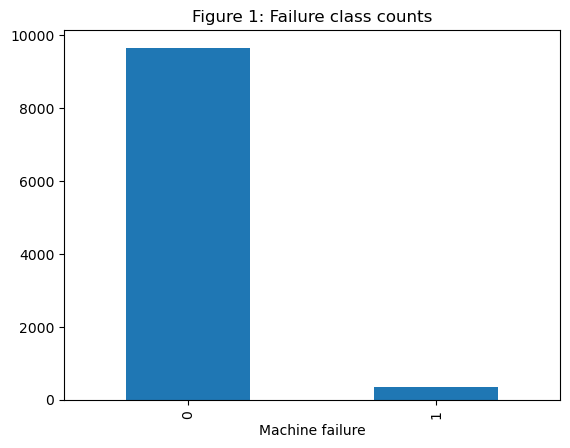

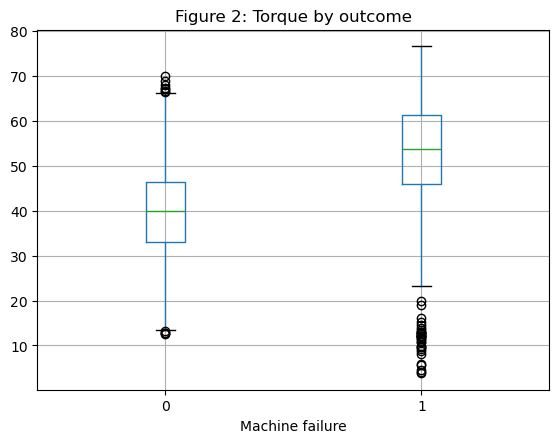

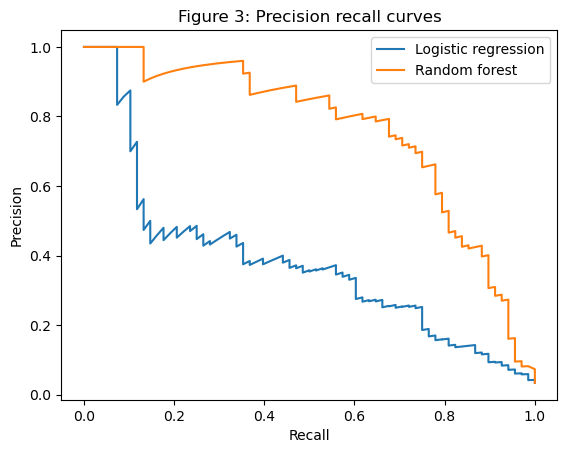

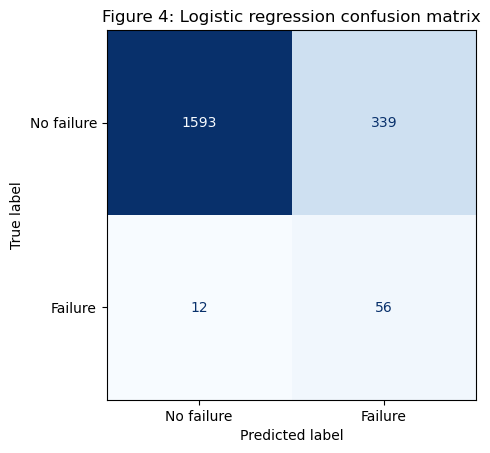

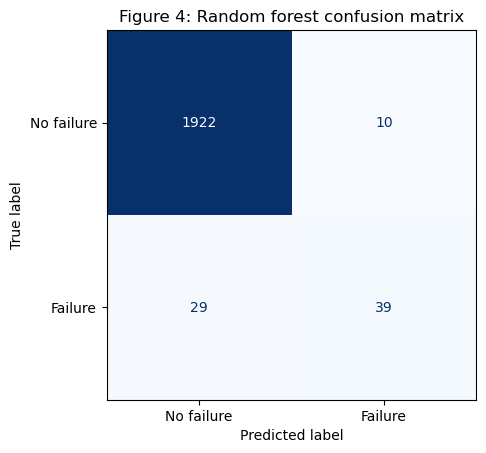

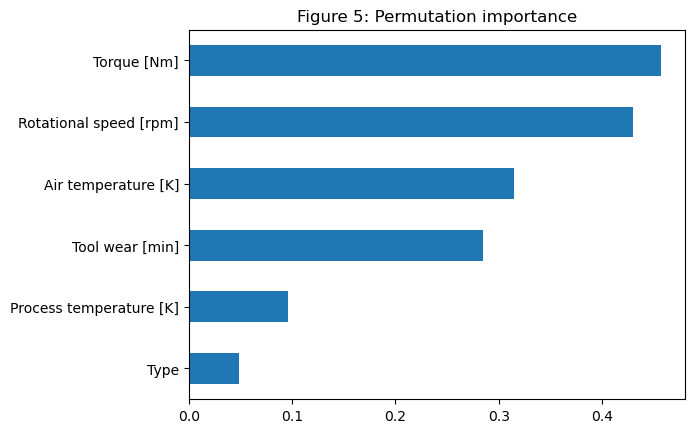

In [3]:
df['Machine failure'].value_counts().sort_index().plot.bar(title='Figure 1: Failure class counts'); plt.show()
df.boxplot(column='Torque [Nm]', by='Machine failure'); plt.suptitle(''); plt.title('Figure 2: Torque by outcome'); plt.show()
for name, model in models.items():
    precision, recall, _ = precision_recall_curve(y_test, model.predict_proba(X_test)[:,1])
    plt.plot(recall, precision, label=name)
plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title('Figure 3: Precision recall curves'); plt.legend(); plt.show()
for name, model in models.items():
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, display_labels=['No failure','Failure'], cmap='Blues', colorbar=False)
    plt.title('Figure 4: ' + name + ' confusion matrix'); plt.show()
importance = permutation_importance(models['Random forest'], X_test, y_test, scoring='average_precision', n_repeats=5, random_state=42)
pd.Series(importance.importances_mean, index=features).sort_values().plot.barh(title='Figure 5: Permutation importance'); plt.show()


## Reproducibility notes
Python packages: pandas, numpy, matplotlib, scikit learn. This analysis is a retrospective exercise on synthetic records. No live deployment or real world reliability claims are supported.